# 12 — Pemetaan Buku ke Banyak Kompetensi (Multi-Competency Mapping)

> **Proyek NLP BPJS Kesehatan** | Fokus utama: **Book-to-Multiple-Competency Recommendation**.
Model menerima judul dan abstrak buku (katalog maupun buku baru) kemudian menghasilkan beberapa kompetensi yang relevan (1 hingga 5 kompetensi).

Seluruh 6 model diuji secara konsisten:
1. **BM25** (Sparse Lexical Keyword Matching)
2. **TF-IDF** (Sublinear N-Gram Vector Space Model)
3. **FastText** (Subword Semantic Averaging Vector)
4. **Multilingual E5** (Dense Bi-Encoder 768-d)
5. **BGE-M3** (Dense Multilingual Bi-Encoder 1024-d)
6. **BGE Reranker v2 M3** (Cross-Encoder Transformer)

## A. Setup Lingkungan dan Pemuatan Data

In [6]:
from pathlib import Path
import sys, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if not (ROOT / 'data').exists():
    ROOT = ROOT.parent
assert (ROOT / 'data' / 'dataset_buku_2000.csv').exists(), 'Dataset buku belum ditemukan'
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

OUT = ROOT / 'outputs'
FIG = ROOT / 'figures'
OUT.mkdir(exist_ok=True)
FIG.mkdir(exist_ok=True)

MODEL_NAMES = ['bm25', 'tfidf', 'e5', 'bge_m3', 'bge_reranker', 'fasttext']
books = pd.read_csv(ROOT / 'data' / 'dataset_buku_2000.csv', dtype={'book_id': str}).fillna('')
profiles = pd.read_csv(OUT / 'profil_kompetensi_query.csv', dtype={'competency_id': str}).fillna('')
assert books['book_id'].is_unique and profiles['competency_id'].is_unique
print(f'Katalog: {len(books)} buku | Definisi Kompetensi: {len(profiles)}')

Katalog: 973 buku | Definisi Kompetensi: 67


C:\Users\AUREL ELVIOLITA\AppData\Local\Temp\ipykernel_12836\1808299960.py:20: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  books = pd.read_csv(ROOT / 'data' / 'dataset_buku_2000.csv', dtype={'book_id': str}).fillna('')
C:\Users\AUREL ELVIOLITA\AppData\Local\Temp\ipykernel_12836\1808299960.py:21: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  profiles = pd.read_csv(OUT / 'profil_kompetensi_query.csv', dtype={'competency_id': str}).fillna('')


## B. Audit Kelengkapan Matriks Seluruh Model (65.191 Pasangan per Model)

In [7]:
from src.multi_competency import read_model_scores, rank_competencies

scores = {}
audit_rows = []
for model_name in MODEL_NAMES:
    try:
        frame = read_model_scores(OUT, model_name, books['book_id'], profiles['competency_id'])
        scores[model_name] = frame
        audit_rows.append({
            'model': model_name,
            'status': 'VALID',
            'pasangan': len(frame),
            'min_score': round(frame['skor_asli'].min(), 4),
            'max_score': round(frame['skor_asli'].max(), 4),
            'mean_score': round(frame['skor_asli'].mean(), 4)
        })
    except Exception as e:
        audit_rows.append({'model': model_name, 'status': 'BELUM_VALID', 'catatan': str(e)})

audit_df = pd.DataFrame(audit_rows)
display(audit_df)
assert len(scores) == 6, 'Semua 6 model harus valid'

,model,status,pasangan,min_score,max_score,mean_score
0,bm25,VALID,65191,0.0000,25.6679,1.2352
1,tfidf,VALID,65191,0.0000,0.5190,0.0082
2,e5,VALID,65191,0.6821,0.8851,0.7663
3,bge_m3,VALID,65191,0.1565,0.7710,0.4232
4,bge_reranker,VALID,65191,0.0000,0.7148,0.0823
5,fasttext,VALID,65191,0.6055,0.9856,0.8863


## C. Memetakan Satu Buku ke Seluruh Kompetensi

In [8]:
book_id_contoh = str(books.iloc[0]['book_id'])
contoh_book = books.loc[books['book_id'] == book_id_contoh, ['book_id', 'judul', 'abstrak']]
display(contoh_book)

for model_name, frame in scores.items():
    hasil = rank_competencies(frame, book_id_contoh, top_k=5)
    hasil = hasil.merge(profiles[['competency_id', 'competency_name']], on='competency_id', how='left')
    print(f'=== Rekomendasi Top-5 Kompetensi ({model_name}) ===')
    display(hasil[['ranking', 'competency_id', 'competency_name', 'skor_asli']])

,book_id,judul,abstrak
0,BK00001,Business Growth Strategy,"Introduction I wrote this book, “Business Grow..."


=== Rekomendasi Top-5 Kompetensi (bm25) ===


,ranking,competency_id,competency_name,skor_asli
0,1,C001,Business Development,16.055411
1,2,C011,Strategy Management,8.249831
2,3,C019,Innovation Management,7.534576
3,4,C055,IT Planning and Design,6.722688
4,5,C005,Strategic Purchasing,5.130638


=== Rekomendasi Top-5 Kompetensi (tfidf) ===


,ranking,competency_id,competency_name,skor_asli
0,1,C001,Business Development,0.153217
1,2,C011,Strategy Management,0.076842
2,3,C019,Innovation Management,0.037146
3,4,C055,IT Planning and Design,0.036428
4,5,C050,Learning Management,0.034254


=== Rekomendasi Top-5 Kompetensi (e5) ===


... (3 outputs left out)

=== Rekomendasi Top-5 Kompetensi (bge_reranker) ===


,ranking,competency_id,competency_name,skor_asli
0,1,C001,Business Development,0.508275
1,2,C011,Strategy Management,0.415425
2,3,C052,Culture Development,0.397364
3,4,C005,Strategic Purchasing,0.390157
4,5,C055,IT Planning and Design,0.382576


=== Rekomendasi Top-5 Kompetensi (fasttext) ===


,ranking,competency_id,competency_name,skor_asli
0,1,C013,Competence Management,0.935874
1,2,C064,Release and Deployment,0.922422
2,3,C005,Strategic Purchasing,0.916030
3,4,C055,IT Planning and Design,0.914422
4,5,C018,Knowledge Management,0.912730


## D. Pemetaan Multi-Kompetensi dengan Dynamic Score Thresholding

Formula ambang batas dinamis:
$$T = \max(S_{\min}, S_{\text{top1}} - \Delta)$$
Menghasilkan 1 hingga 5 kompetensi yang relevan per buku secara adaptif.

In [9]:
multi_path = OUT / 'buku_multikompetensi_per_model.csv'
assert multi_path.exists(), 'File buku_multikompetensi_per_model.csv belum ada'
multi_df = pd.read_csv(multi_path, dtype={'book_id': str})
print(f'Total baris pemetaan multi-kompetensi: {len(multi_df):,}')

# Statistik jumlah kompetensi per buku per model
stat_komp = multi_df.groupby('model')['jumlah_kompetensi_kandidat'].agg(['count', 'min', 'mean', 'max', 'std']).reset_index()
stat_komp.columns = ['Model', 'Total Buku', 'Min Komp/Buku', 'Rata-rata Komp/Buku', 'Max Komp/Buku', 'Std Dev']
display(stat_komp)

Total baris pemetaan multi-kompetensi: 5,838


,Model,Total Buku,Min Komp/Buku,Rata-rata Komp/Buku,Max Komp/Buku,Std Dev
0,bge_m3,973,1,4.709147,5,0.878814
1,bge_reranker,973,1,2.823227,5,1.636642
2,bm25,973,1,1.682425,5,1.071934
3,e5,973,4,4.998972,5,0.032059
4,fasttext,973,1,4.981501,5,0.251880
5,tfidf,973,1,1.043165,3,0.213213


## E. Visualisasi Distribusi Jumlah Kompetensi per Buku

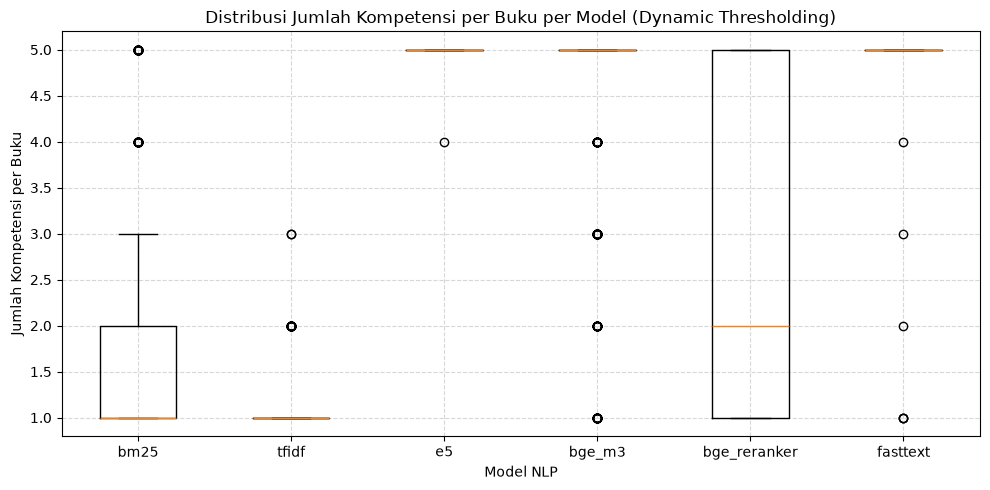

In [10]:
fig, ax = plt.subplots(figsize=(10, 5))
box_data = [multi_df[multi_df['model'] == m]['jumlah_kompetensi_kandidat'].values for m in MODEL_NAMES]
ax.boxplot([np.asarray(data, dtype=np.float64) for data in box_data], tick_labels=MODEL_NAMES)
ax.set_title('Distribusi Jumlah Kompetensi per Buku per Model (Dynamic Thresholding)')
ax.set_ylabel('Jumlah Kompetensi per Buku')
ax.set_xlabel('Model NLP')
ax.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig(FIG / 'distribusi_kompetensi_per_buku_nb12.png', dpi=150)
plt.show()

## F. Kesimpulan Tahap

1. Seluruh 6 model telah berhasil memetakan katalog 973 buku ke multi-kompetensi.
2. Dynamic thresholding menghasilkan rata-rata 1–5 kompetensi per buku yang adaptif terhadap profil skor masing-masing algoritma.
3. Hasil pemetaan siap diuji pada notebook 13 dan dievaluasi secara independen pada notebook 14.